# Submission Demo — two-camera (fr+rl) localization

**Kernel:** `pixel-racers`  ·  **Backend:** `sp_nv_nn` (SuperPoint local + NetVLAD global + mutual-NN match)

Input is a raw `.mcap`. Calib / GT / motion are extracted from the bag: training uses `state_estimation`; **test** uses `/constructor0/validation/twist` + `accel` (same `state_estimation.csv` schema, no pose columns).

### Data flow
```
raw mcap
  ├─ tools/extract_assets.py → camera_info / tf_static / track_bounds / state_estimation.csv
  └─ tools/extract_gt.py     → gt.csv  (from /tf, eval only)
        │
  Lap windows in eval (GT line crossings); predict uses full bag or manual windows
        │
  ┌───────────────┬────────────────────────┬──────────────────────────┐
  Option 1         Option 2                  Option 3
  motion only      two-camera localization   EKF fusion
  SE dead reckoning       fr/rl online loc → se2 fusion   SE predict + fr/rl extrap → se2 → EKF R(s)
        │               │                           │
        └──── each option: submission.csv (timestamp_ns,x,y,yaw) ────┘
              eval also metrics + tools/evaluate.py score
```

| Option | Uses cameras | Description |
|---|---|---|
| 1 motion only | **No** | Integrate v/a/ω from `state_estimation`, sample at two-camera t_last |
| 2 two-camera | **Yes** | fr+rl PnP loc → nearest-stamp ω-weighted SE(2) fusion (no EKF) |
| 3 EKF fusion | **Yes** | SE predict + fr/rl extrap to t_last → se2 → EKF, R(s)=σ(s)² |

Plot outline: **racing line** + **track_left/right** (eval from bag; predict from `track-model/track_bounds.json` + `map.mcap`). Query maps: `sfm-model/map_{fr,rl}_lap2+4` (`build_meta` must be clahe_highlight_v1).

Each option cell documents the flow in markdown and runs explicit pipeline steps; after each option you get a combined-lap figure + vertical evaluate table.
Summary cell: three-way trajectory overlay + metric bars. Final cell: export `evaluate_table.csv`.

`MODE="eval"` (training+GT, metrics) / `MODE="predict"` (test, submission only). First localize run is slow; cache reuse on repeat.

**Predict initial pose:** set **`INIT_POSE_XYYAW`** in the **User configuration** cell (or use **`run_init_pose.ipynb`**).


## User configuration
Edit this cell to switch train/test mcap, **eval / predict**, eval lap list, and (predict only) initial pose (**eval ignores `INIT_POSE_XYYAW`; uses GT**).


In [32]:
TRAIN_MCAP = "/Users/hbai/SchubKI/c0_2026-10-13_22-53-42_camloc/c0_2026-10-13_22-53-42_camloc_0.mcap"
TEST_MCAP  = "/Users/hbai/SchubKI/rosbag_2026-10-13_16-08-46_cameras_lap/rosbag_2026-10-13_16-08-46_cameras_lap_0.mcap"
MODE = "eval"            # eval=train+GT | predict=test (no GT)
LAPS = [5, 6, 7]         # eval laps; None=all complete laps
LAPS_JSON = "/Users/hbai/SchubKI/PixelRacers/lapdata/laps.json"  # None=auto-detect from GT
INIT_POSE_XYYAW = (-120.0, 695.0, -1.842)  # predict only; ignored in eval
INIT_POSE_T0_NS = None



## SETUP
Load config, extract assets from mcap (camera_info / tf_static / track_bounds / state_estimation; GT in eval), calibrations, **track-model/map.mcap** outline, lap windows; verify **CLAHE sfm-model** maps.
`ctx` holds assets, calib, racing line, track bounds, windows, and per-option result cache.


In [33]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")   # avoid macOS libomp conflict
os.environ.setdefault("OMP_NUM_THREADS", "1")
import sys
from pathlib import Path
HERE = Path.cwd()
if HERE.name != "submission-demo" and (HERE / "submission-demo").is_dir():
    HERE = HERE / "submission-demo"
for p in (str(HERE), str(HERE / "tools")):
    if p not in sys.path:
        sys.path.insert(0, p)
%matplotlib inline
_local = {"pipeline", "plots", "sfm_core", "sfm_features", "sfm_localize",
          "fusion", "motion_ekf", "metrics", "obs_sigma", "mcap_io", "assets_io", "laps"}
for _m in list(sys.modules):
    if _m in _local or _m.split(".")[0] in _local:
        del sys.modules[_m]
import numpy as np
import pandas as pd
import pipeline as P
import motion_ekf as mek
import fusion, obs_sigma
WINDOWS = None         # manual (start_ns,end_ns) list; usually use LAPS / LAPS_JSON
CAMS         = ("fr", "rl")
REF_CAMERA   = "fr"
BACKEND      = "sp_nv_nn"
QUERY_STRIDE = 1
TOP_K        = 5
OVERRIDE_QUERY = False   # True after changing maps / preprocessing
TRACK_MCAP = str(HERE / "track-model" / "map.mcap")  # Yas track model (plot outline + s/n projection)
cfg = P.SubmissionConfig(
    train_mcap=TRAIN_MCAP, test_mcap=TEST_MCAP, mode=MODE,
    laps=LAPS, windows=WINDOWS, laps_json=LAPS_JSON,
    cams=CAMS, ref_camera=REF_CAMERA, backend=BACKEND,
    query_stride=QUERY_STRIDE, top_k=TOP_K, override_query=OVERRIDE_QUERY,
    track_mcap=TRACK_MCAP,
    sfm_model_dir=str(HERE / "sfm-model"),
    init_pose_xyyaw=INIT_POSE_XYYAW,
    init_pose_t0_ns=INIT_POSE_T0_NS,
)
map_report = P.verify_sfm_maps(cfg)  # must be clahe_highlight_v1 (matches query preprocessing)
ctx = P.ensure_assets(cfg)
print("run dir:", cfg.run_dir)
print("motion:", ctx.assets.motion_source, "se rows:", len(ctx.assets.se))
print("windows:", [w["name"] for w in ctx.windows])
print("sfm maps:", {k: v["preprocess_version"] for k,v in map_report.items()})
print("track outline:", list(ctx.track_outline.keys()), "lap_m=", round(ctx.track_line.lap, 1))
print("init_pose_xyyaw:", cfg.init_pose_xyyaw, "(ignored in eval)" if MODE == "eval" else "")

def show_eval_table(df):
    """Vertical metrics table (evaluate.py fields); displays once, no duplicate return value."""
    if df is None or len(df) == 0:
        return
    from IPython.display import display
    display(P.evaluate_table_vertical(df))




[setup] map_fr CLAHE ok=True bytes=507704527 preprocess=clahe_highlight_v1
[setup] map_rl CLAHE ok=True bytes=521878992 preprocess=clahe_highlight_v1
[setup] mode=eval windows=['lap5', 'lap6', 'lap7']
[setup] cams=('fr', 'rl') backend=sp_nv_nn has_gt=True motion=state_estimation se_rows=126574 se_pose=True
[setup] track_model=/Users/hbai/SchubKI/PixelRacers/submission-demo/track-model/map.mcap lap=2976.9m outline=['racing_line', 'track_left', 'track_right']
run dir: /Users/hbai/SchubKI/PixelRacers/submission-demo/outputs/eval_c0_2026-10-13_22-53-42_camloc_0
motion: state_estimation se rows: 126574
windows: ['lap5', 'lap6', 'lap7']
sfm maps: {'fr': 'clahe_highlight_v1', 'rl': 'clahe_highlight_v1'}
track outline: ['racing_line', 'track_left', 'track_right'] lap_m= 2976.9
init_pose_xyyaw: (-120.0, 695.0, -1.842) (ignored in eval)


## Option 1 — motion prediction only

**Dead reckoning only — no camera features.** Integrates body-frame v/a/ω from `state_estimation`.

**Flow**
1. `window_se` — slice SE to lap window
2. `init_pose` — eval: **GT**; predict: **`INIT_POSE_XYYAW`** / SE / loc cache
3. `camera_tlast` — two-camera timeline
4. `run_mode_a_se_predict_at` — integrate and sample
5. `finalize` — write `submission.csv`; eval metrics + combined figure via `present_option`


[motion_only] wrote /Users/hbai/SchubKI/PixelRacers/submission-demo/outputs/eval_c0_2026-10-13_22-53-42_camloc_0/lap5/motion_only/submission.csv emit=1523/1523 (100.0%) pos_rmse_xy=11.186m
[motion_only] wrote /Users/hbai/SchubKI/PixelRacers/submission-demo/outputs/eval_c0_2026-10-13_22-53-42_camloc_0/lap6/motion_only/submission.csv emit=1205/1205 (100.0%) pos_rmse_xy=12.720m
[motion_only] wrote /Users/hbai/SchubKI/PixelRacers/submission-demo/outputs/eval_c0_2026-10-13_22-53-42_camloc_0/lap7/motion_only/submission.csv emit=1095/1095 (100.0%) pos_rmse_xy=10.121m


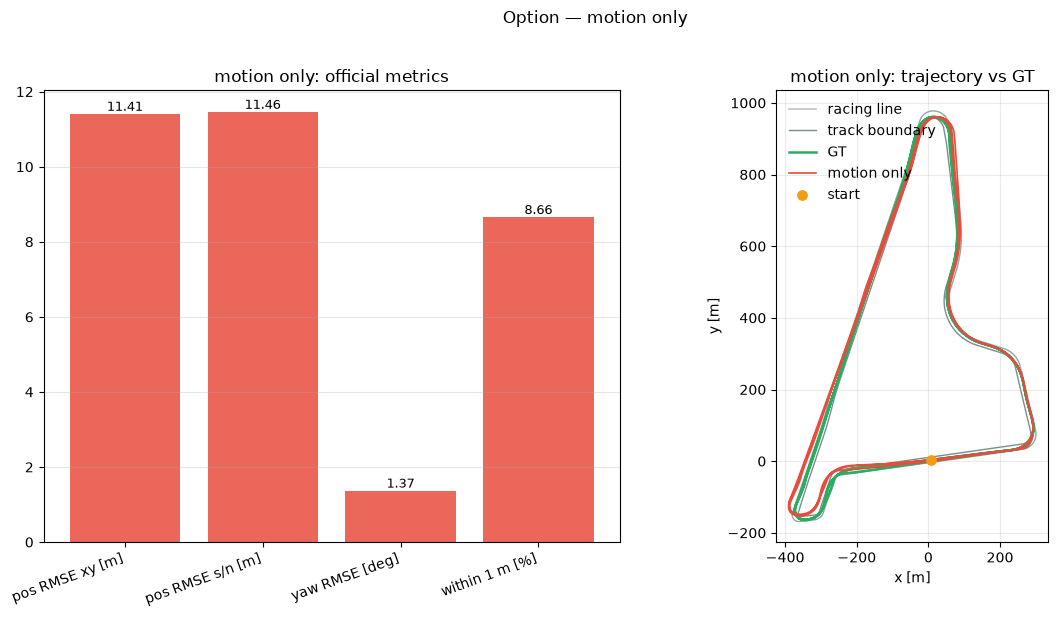

,metric,value
0,poses submitted,3823
1,poses evaluated,3823
2,coverage (1 s bins) [%],100.0
3,min coverage to rank [%],90.0
4,position RMSE [m] (score),11.410
5,position median [m],7.826
6,position p95 [m],20.976
7,lateral RMSE [m],9.046
8,longitudinal RMSE [m],6.954
9,yaw RMSE [deg],1.370


In [34]:
for w in ctx.windows:
    se_win = P.window_se(ctx, w)                         # 1. slice SE to window
    x0, y0, yaw0, t0 = P.init_pose(ctx, se_win, w, run_localize=False)  # 2. init pose (INIT_POSE_XYYAW / GT / loc)
    t_last = P.camera_tlast(ctx, w)                      # 3. camera timestamps (no features)
    pred = mek.run_mode_a_se_predict_at(                 # 4. dead reckon + sample
        se_win, t_last, x0=x0, y0=y0, yaw0=yaw0)
    out_dir = cfg.run_dir / w["name"] / "motion_only"
    P.finalize(ctx, pred, out_dir, "motion_only", w,     # 5. write submission + metrics + figure
               n_total=len(pred), show_plots=False)
# merged laps: trajectory/metrics figure + evaluate.py table (window=all)
show_eval_table(P.present_option(ctx, "motion_only", show_plots=True, print_evaluate_report=False))





## Option 2 — two-camera localization (fr + rl)

**Vision only — offline fr+rl SE(2) fusion, no EKF, no temporal extrapolation.**

**Flow**
1. `ensure_loc_tables` — localize fr and rl (or read cache)
2. `fuse_loc_tables_se2` — nearest-stamp ω-weighted fusion
3. Keep `ok` rows → `submission.csv`
4. `finalize` + `present_option`


[setup] loading feature backend: sp_nv_nn
[fr] map frames=2689 points=164183
[fr] query frames=1523 window=[1791918837334833042,1791918989608528778]


feat-fr:   0%|          | 0/1523 [00:00<?, ?frm/s]

[fr] localized 1523 ok=1505 in 142.3s -> /Users/hbai/SchubKI/PixelRacers/submission-demo/outputs/eval_c0_2026-10-13_22-53-42_camloc_0/loc/lap5/loc_fr/errors.csv
[rl] map frames=2689 points=124268
[rl] query frames=1523 window=[1791918837334833042,1791918989608528778]


feat-rl:   0%|          | 0/1523 [00:00<?, ?frm/s]

[rl] localized 1523 ok=1302 in 147.3s -> /Users/hbai/SchubKI/PixelRacers/submission-demo/outputs/eval_c0_2026-10-13_22-53-42_camloc_0/loc/lap5/loc_rl/errors.csv
[two_cam] wrote /Users/hbai/SchubKI/PixelRacers/submission-demo/outputs/eval_c0_2026-10-13_22-53-42_camloc_0/lap5/two_cam/submission.csv emit=1516/1523 (99.5%) pos_rmse_xy=1.868m
[fr] map frames=2689 points=164183
[fr] query frames=1205 window=[1791918989608528778,1791919110125677038]


...

[rl] localized 1205 ok=973 in 121.7s -> /Users/hbai/SchubKI/PixelRacers/submission-demo/outputs/eval_c0_2026-10-13_22-53-42_camloc_0/loc/lap6/loc_rl/errors.csv
[two_cam] wrote /Users/hbai/SchubKI/PixelRacers/submission-demo/outputs/eval_c0_2026-10-13_22-53-42_camloc_0/lap6/two_cam/submission.csv emit=1205/1205 (100.0%) pos_rmse_xy=3.128m
[fr] map frames=2689 points=164183
[fr] query frames=1095 window=[1791919110125677038,1791919219632923498]


feat-fr:   0%|          | 0/1095 [00:00<?, ?frm/s]

[fr] localized 1095 ok=1086 in 97.1s -> /Users/hbai/SchubKI/PixelRacers/submission-demo/outputs/eval_c0_2026-10-13_22-53-42_camloc_0/loc/lap7/loc_fr/errors.csv
[rl] map frames=2689 points=124268
[rl] query frames=1095 window=[1791919110125677038,1791919219632923498]


feat-rl:   0%|          | 0/1095 [00:00<?, ?frm/s]

[rl] localized 1095 ok=822 in 107.0s -> /Users/hbai/SchubKI/PixelRacers/submission-demo/outputs/eval_c0_2026-10-13_22-53-42_camloc_0/loc/lap7/loc_rl/errors.csv
[two_cam] wrote /Users/hbai/SchubKI/PixelRacers/submission-demo/outputs/eval_c0_2026-10-13_22-53-42_camloc_0/lap7/two_cam/submission.csv emit=1095/1095 (100.0%) pos_rmse_xy=1.144m


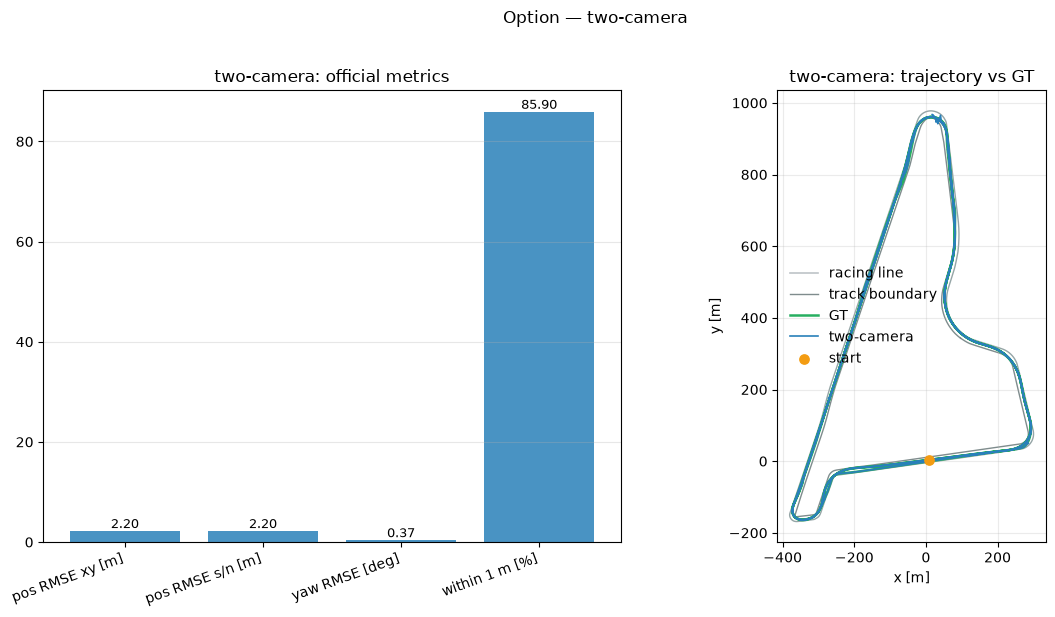

,metric,value
0,poses submitted,3816
1,poses evaluated,3816
2,coverage (1 s bins) [%],100.0
3,min coverage to rank [%],90.0
4,position RMSE [m] (score),2.203
5,position median [m],0.255
6,position p95 [m],2.422
7,lateral RMSE [m],0.815
8,longitudinal RMSE [m],2.046
9,yaw RMSE [deg],0.370


In [35]:
for w in ctx.windows:
    tables = P.ensure_loc_tables(ctx, w)                 # 1. fr/rl online localize (or cache)
    fused = fusion.fuse_loc_tables_se2(                  # 2. nearest-stamp omega-weighted se2 fusion
        tables, ref_camera=ctx.cfg.ref_camera)
    ok = fused[fused.ok].reset_index(drop=True)          # 3. keep fused ok frames only
    pred = pd.DataFrame({
        "timestamp_ns": ok.stamp_ns.to_numpy(np.int64),
        "x": ok.pred_x.to_numpy(float),
        "y": ok.pred_y.to_numpy(float),
        "yaw": ok.pred_yaw.to_numpy(float),
    })
    out_dir = cfg.run_dir / w["name"] / "two_cam"
    out_dir.mkdir(parents=True, exist_ok=True)
    fused.to_csv(out_dir / "errors_se2.csv", index=False)
    P.finalize(ctx, pred, out_dir, "two_cam", w,         # 4. write submission + metrics (denom=all sync frames) + figure
               n_total=len(fused), show_plots=False)
# merged laps: trajectory/metrics figure + evaluate.py table (window=all)
show_eval_table(P.present_option(ctx, "two_cam", show_plots=True, print_evaluate_report=False))





## Option 3 — EKF fusion (fr + rl)

**SE(2) EKF** with motion prediction and vision updates; async cameras extrapolated to `t_last`; R(s)=σ(s)².

**Flow**
1. `write_process_noise_yaml` — process noise Q
2. `ensure_loc_tables` — fr/rl localize (cache)
3. `init_pose` — INIT_POSE_XYYAW / loc
4. `build_sync_buckets` + `run_mode_b_ekf`
5. `finalize` + `present_option`


[loc] cache hit all cams window=lap5 (no re-query)
[ekf] wrote /Users/hbai/SchubKI/PixelRacers/submission-demo/outputs/eval_c0_2026-10-13_22-53-42_camloc_0/lap5/ekf/submission.csv emit=1523/1523 (100.0%) pos_rmse_xy=1.022m
[loc] cache hit all cams window=lap6 (no re-query)
[ekf] wrote /Users/hbai/SchubKI/PixelRacers/submission-demo/outputs/eval_c0_2026-10-13_22-53-42_camloc_0/lap6/ekf/submission.csv emit=1205/1205 (100.0%) pos_rmse_xy=1.499m
[loc] cache hit all cams window=lap7 (no re-query)
[ekf] wrote /Users/hbai/SchubKI/PixelRacers/submission-demo/outputs/eval_c0_2026-10-13_22-53-42_camloc_0/lap7/ekf/submission.csv emit=1095/1095 (100.0%) pos_rmse_xy=0.873m


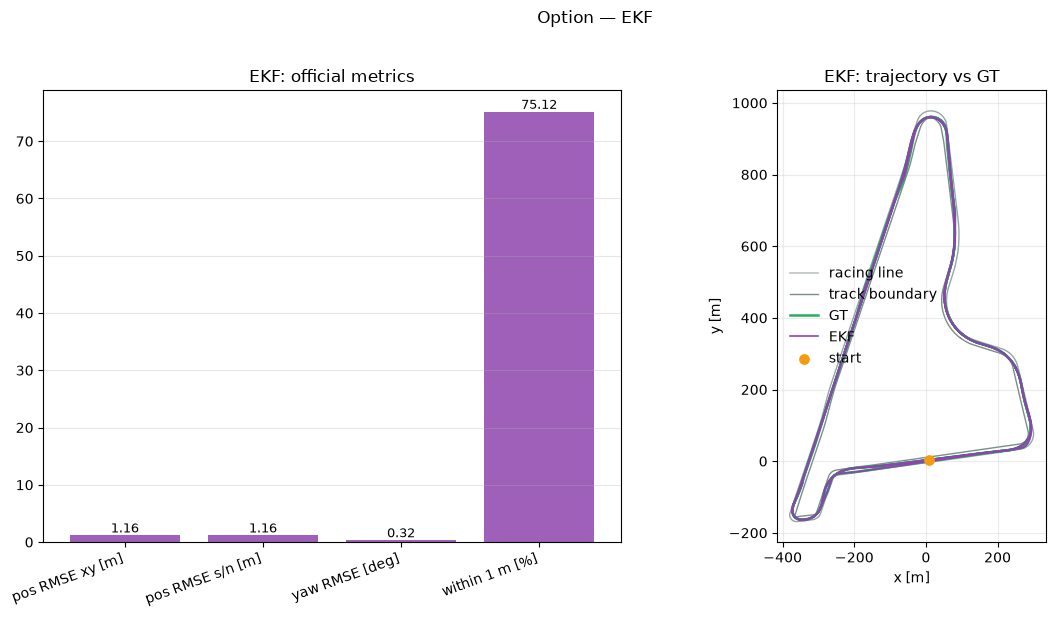

,metric,value
0,poses submitted,3823
1,poses evaluated,3823
2,coverage (1 s bins) [%],100.0
3,min coverage to rank [%],90.0
4,position RMSE [m] (score),1.159
5,position median [m],0.657
6,position p95 [m],2.003
7,lateral RMSE [m],0.620
8,longitudinal RMSE [m],0.979
9,yaw RMSE [deg],0.317


In [36]:
for w in ctx.windows:
    se_win = P.window_se(ctx, w)
    noise = mek.write_process_noise_yaml(Path(cfg.noise_json))   # 1. process noise Q
    ncfg = mek.NoiseCfg.from_dict(noise)
    tables = P.ensure_loc_tables(ctx, w)                         # 2. fr/rl localize (cache)
    x0, y0, yaw0, t0 = P.init_pose(                            # init: INIT_POSE_XYYAW / loc
        ctx, se_win, w, loc_tables=tables, run_localize=False)
    buckets = mek.build_sync_buckets(                            # 3. fr/rl sync buckets
        tables, ref_camera=cfg.ref_camera, cams=cfg.cams)
    pred, sim = mek.run_mode_b_ekf(                              # 4. predict -> extrapolate -> se2 -> EKF update R(s)
        se_win, buckets, ncfg,
        x0=x0, y0=y0, yaw0=yaw0, t0_ns=t0,
        sigma_of_s_fn=obs_sigma.sigma_of_s,
        track_line=ctx.track_line, cams=cfg.cams,
    )
    out_dir = cfg.run_dir / w["name"] / "ekf"
    (out_dir / "sim").mkdir(parents=True, exist_ok=True)
    sim.to_csv(out_dir / "sim" / "ekf_sim.csv", index=False)
    P.finalize(ctx, pred, out_dir, "ekf", w,                    # 5. write submission + metrics + figure
               n_total=len(pred), show_plots=False)
# merged laps: trajectory/metrics figure + evaluate.py table (window=all)
show_eval_table(P.present_option(ctx, "ekf", show_plots=True, print_evaluate_report=False))





## Summary comparison
`run_summary`: three-option **trajectory overlay + metric bars** (`window=all`). Scoring table is shown once per Option cell (vertical); this cell does not repeat the table. Predict mode lists submission paths only.


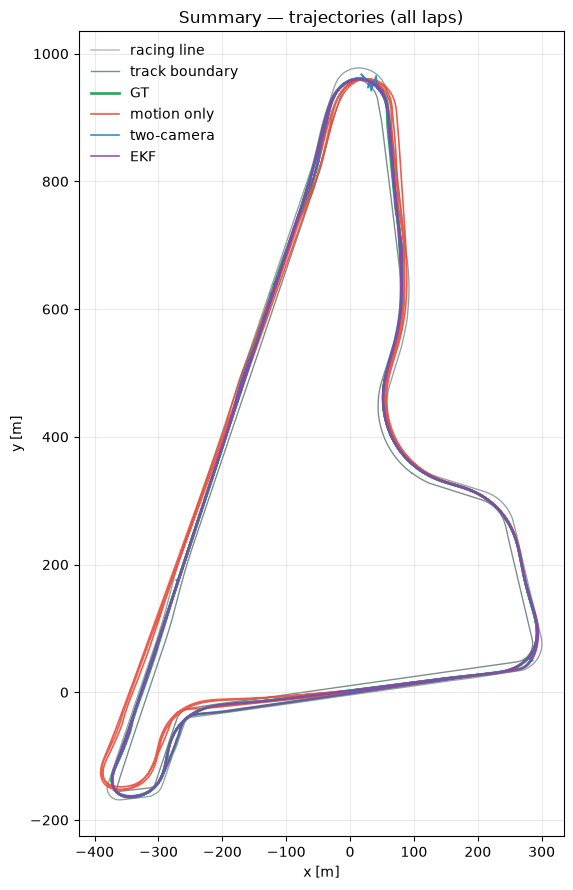

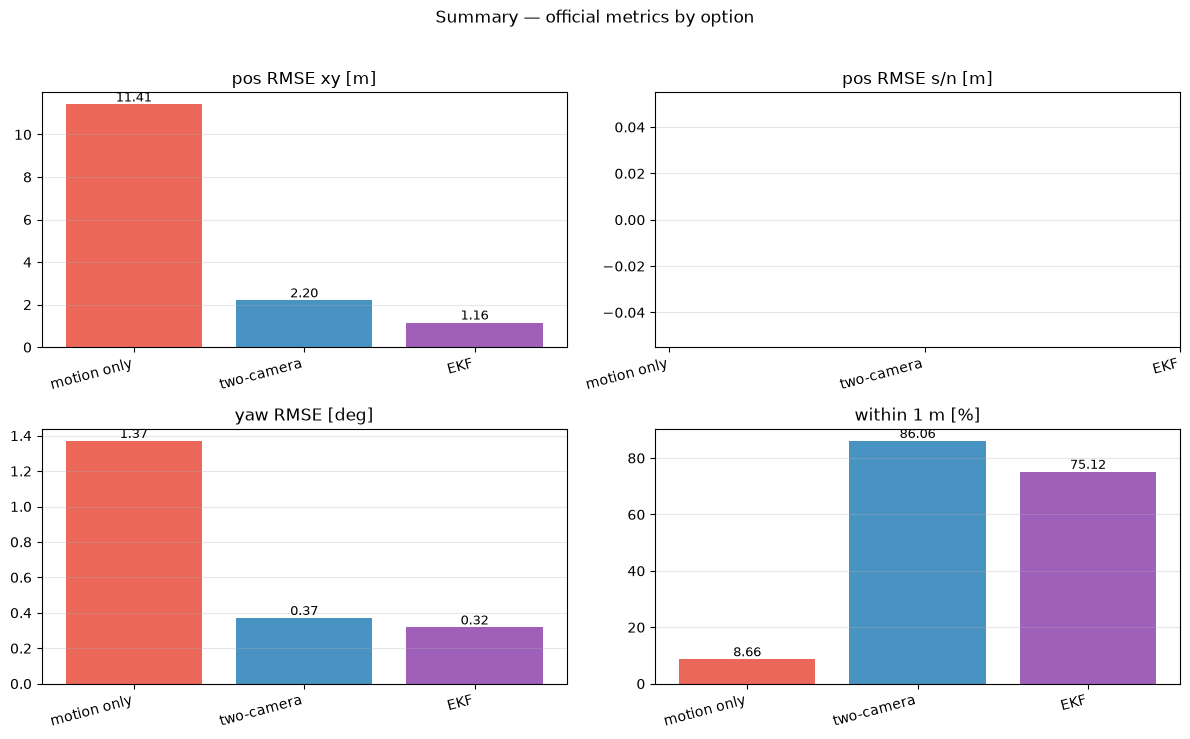


=== metrics (all laps) ===
       mode  pos_rmse_xy_m  pos_rmse_sn_m  yaw_rmse_deg  within_1m_of_all_%
motion_only         11.410            NaN         1.370               8.658
    two_cam          2.203            NaN         0.370              86.059
        ekf          1.159            NaN         0.317              75.124


In [37]:
mdf = P.run_summary(ctx, show_plots=True, aggregate_laps=True)


## Deliverables
- **predict**: list each option's `submission.csv` path.
- **eval**: metrics already shown in Option cells; this cell writes `{run_dir}/compare/evaluate_table.csv` (wide table for export).


In [38]:
if ctx.assets.has_gt:
    P.build_evaluate_table(ctx, evaluate=True, print_reports=False, per_lap=False)
    print(f"Saved: {ctx.cfg.run_dir / 'compare' / 'evaluate_table.csv'}")
else:
    P.list_outputs(ctx, evaluate=False)


Saved: /Users/hbai/SchubKI/PixelRacers/submission-demo/outputs/eval_c0_2026-10-13_22-53-42_camloc_0/compare/evaluate_table.csv
